# Phase 4 — Feature Engineering: FD002
**Notebook:** `06b_Feature_Engineering_FD002.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

The goal is the same as FD001's Phase 4: turn each engine's history into model inputs **without using any future information**.
- **LR, RF, XGBoost:** one fixed-length vector per cycle (current values + rolling mean / std / slope + `cycle`).
- **LSTM:** a chronological window of recent cycles.

**No new code files.** `src/feature_engineering.py` from FD001 is reused unchanged. It works on *any* scaled data, including FD002's per-regime z-scores. This notebook only **loads** the frozen Phase 3 pipeline and decides two things on validation data:

| Decision | Candidates | Why it needs testing for FD002 |
|---|---|---|
| Rolling window | 0, 10, 20, 30, 50, 80, 100, 150, 200, 300, 400 (= whole life) | FD002's cycle-to-cycle noise is larger, so longer averaging may help |
| LSTM input | 15 or 21 cycles of sensors, or 21 cycles of sensors + rolling means | A 21-cycle limit is forced by the shortest test engine |



## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FD, SEED = "FD002", 42
PROC_DIR  = PROJECT_DIR / "data" / "processed" / FD
PREP_DIR  = PROJECT_DIR / "models" / FD / "preprocessing"
FIG_DIR   = PROJECT_DIR / "reports" / "figures" / FD
FE_REPORT = PROJECT_DIR / "reports" / "feature_engineering" / FD
FE_REPORT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
print("Device:", DEVICE)

Mounted at /content/drive
Device: cuda


## Cell 2 — Load the frozen Phase 3 artifacts
Nothing is re-fitted here. The regime scalers, split and validation points all come from disk, exactly as the API will load them later.

**Small repair, included automatically:** the `06_Preprocessing_FD002` notebook saved `split.json` with the keys `train_ids` / `val_ids`, while FD001 uses `train_engine_ids` / `val_engine_ids`. The engine IDs themselves are correct. This cell adds the standard key names so every later notebook reads FD001 and FD002 the same way. It only renames keys and never changes which engines are in which set.

In [2]:
# Cell 2 — Load artifacts (+ standardise split.json key names)
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.regime_preprocessing as rp, src.model_training as mt
for m in (dl, pp, ev, fe, rp, mt):
    importlib.reload(m)

split_path = PROC_DIR / "split.json"
split = json.loads(split_path.read_text())
if "train_engine_ids" not in split:
    split["train_engine_ids"], split["val_engine_ids"] = split.pop("train_ids"), split.pop("val_ids")
    split_path.write_text(json.dumps(split))
    print("split.json keys standardised (engine IDs unchanged)")
train_ids, val_ids = split["train_engine_ids"], split["val_engine_ids"]

meta = json.loads((PREP_DIR / "pipeline_metadata.json").read_text())
prep = rp.load_preprocessor(PREP_DIR)
cuts = pd.read_csv(PROC_DIR / "val_cut_points.csv")
CAP, B, MAX_SEQ = meta["rul_cap"], prep.feature_cols, meta["max_lstm_seq_len"]

d = dl.load_dataset(FD, RAW_DIR)
full = pp.add_train_rul(d["train"], cap=CAP)                          # capped training target
tr_s = prep.transform(full[full.engine_id.isin(train_ids)]).reset_index(drop=True)
va_s = prep.transform(full[full.engine_id.isin(val_ids)]).reset_index(drop=True)
print(f"{type(prep).__name__} | cap {CAP} | {len(B)} base sensors | max LSTM length {MAX_SEQ}")
print(f"train rows {len(tr_s)} | val rows {len(va_s)} | validation points {len(cuts)}")

split.json keys standardised (engine IDs unchanged)
RegimePreprocessor | cap 125 | 14 base sensors | max LSTM length 21
train rows 43206 | val rows 10553 | validation points 520


**Expected:** `RegimePreprocessor | cap 125 | 14 base sensors | max LSTM length 21`, then `train rows 43206 | val rows 10553 | validation points 520`. The first time you run it, you'll also see `split.json keys standardised`.

## Cell 3 — Prove the features use no future data (on FD002's regime-scaled data)
Same three checks as FD001: future data can't affect past features, the window restarts for each engine, and the slope matches `np.polyfit`. We use a long window (200) here because that's the case most at risk of mixing engines.

In [3]:
# Cell 3 — Causality and correctness checks
W_TEST = 200
f1 = fe.add_rolling_features(va_s, B, W_TEST)
eid = val_ids[0]
corrupted = va_s.copy()
corrupted.loc[(corrupted.engine_id == eid) & (corrupted.cycle > 60), B] += 50     # corrupt the FUTURE
f2 = fe.add_rolling_features(corrupted, B, W_TEST)
past = (f1.engine_id == eid) & (f1.cycle <= 60)
cols = [c for c in f1.columns if c != "RUL"]
assert np.allclose(f1.loc[past, cols].values, f2.loc[past, cols].values)
print("✅ Causal: changing an engine's future does not change its past features")

first = f1.groupby("engine_id").head(1)
assert np.allclose(first[f"{B[0]}_mean_{W_TEST}"], first[B[0]]) and (first[f"{B[0]}_std_{W_TEST}"] == 0).all()
print("✅ Engine boundaries respected (the window restarts for each engine)")

g = f1[f1.engine_id == eid].sort_values("cycle")
assert np.isclose(np.polyfit(g.cycle.values[:50], g[B[0]].values[:50], 1)[0], g[f"{B[0]}_slope_{W_TEST}"].values[49])
print("✅ Rolling slope matches np.polyfit (window still filling: first 50 cycles)")

✅ Causal: changing an engine's future does not change its past features
✅ Engine boundaries respected (the window restarts for each engine)
✅ Rolling slope matches np.polyfit (window still filling: first 50 cycles)


## Cell 4 — What the features look like for one engine

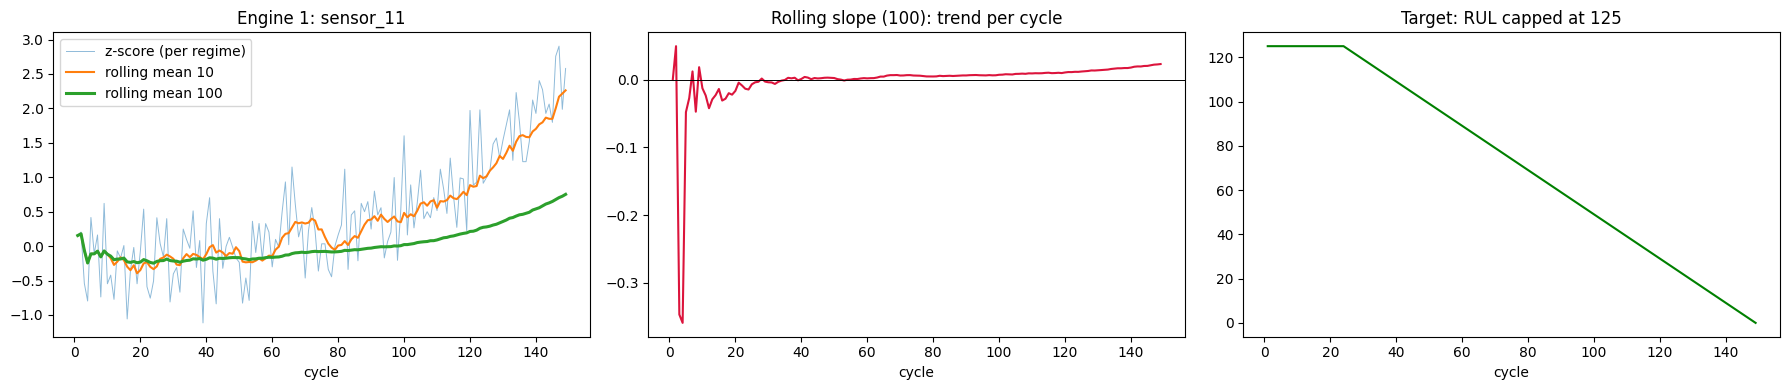

In [4]:
# Cell 4 — sensor_11: per-regime z-score, short vs long rolling mean, and long slope
eng = train_ids[0]
g = tr_s[tr_s.engine_id == eng]
g = fe.add_rolling_features(fe.add_rolling_features(g, ["sensor_11"], 10), ["sensor_11"], 100)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(g.cycle, g.sensor_11, lw=0.7, alpha=0.5, label="z-score (per regime)")
axes[0].plot(g.cycle, g.sensor_11_mean_10, lw=1.5, label="rolling mean 10")
axes[0].plot(g.cycle, g.sensor_11_mean_100, lw=2.2, label="rolling mean 100")
axes[0].set(title=f"Engine {eng}: sensor_11", xlabel="cycle"); axes[0].legend()
axes[1].plot(g.cycle, g.sensor_11_slope_100, color="crimson"); axes[1].axhline(0, color="black", lw=0.7)
axes[1].set(title="Rolling slope (100): trend per cycle", xlabel="cycle")
axes[2].plot(g.cycle, g.RUL, color="green"); axes[2].set(title=f"Target: RUL capped at {CAP}", xlabel="cycle")
fig.tight_layout(); fig.savefig(FIG_DIR / "11_engineered_features_example.png", dpi=150, bbox_inches="tight"); plt.show()

**What to look for:**
- **The 10-cycle mean** is still jumpy. Even after regime scaling, FD002 readings are noisier than FD001's.
- **The 100-cycle mean** is smooth and rises steadily towards failure.
- **The 100-cycle slope** is close to 0 early on and increases in the last stage of life.

So in FD002 a short window can't separate wear from noise reliably, which is why the window experiment below tests windows longer than FD001's 30.

---
## Cell 5 — Rolling window experiment (tabular models)
Same probes as Phase 3 (Linear Regression + small Random Forest), same 520 validation points, and `cycle` included (it helped consistently in FD001).

**Can the window be longer than the shortest test engine (21 cycles)?** Yes. Rolling features use `min_periods=1`, so for a short engine the "100-cycle mean" is simply the mean of all cycles seen so far. The validation points include histories as short as 21 cycles, so this situation is scored fairly.

**Selection rule (fixed in advance):** take the window with the lowest RF RMSE (RUL ≤ 125). If smaller windows are within **0.5 RMSE** of it, take the smallest of those, because a smaller window adapts faster and is cheaper. Then check whether `cycle` still helps at that window.

window   0, cycle=True: LR 21.24 | RF 18.70  (6.7s)
window  10, cycle=True: LR 19.99 | RF 17.48  (29.1s)
window  20, cycle=True: LR 20.25 | RF 16.66  (28.8s)
window  30, cycle=True: LR 20.46 | RF 15.83  (29.3s)
window  50, cycle=True: LR 20.15 | RF 13.74  (29.2s)
window  80, cycle=True: LR 19.90 | RF 12.15  (27.4s)
window 100, cycle=True: LR 19.68 | RF 11.77  (27.4s)
window 150, cycle=True: LR 19.90 | RF 11.49  (28.1s)
window 200, cycle=True: LR 20.30 | RF 10.86  (29.2s)
window 300, cycle=True: LR 20.39 | RF 10.86  (29.6s)
window 400, cycle=True: LR 20.39 | RF 10.81  (28.8s)

Best RF window: 400 (10.81) → chosen by the 0.5 rule: 200 (10.86)
window 200, cycle=False: LR 20.55 | RF 12.23  (29.3s)
cycle feature at window 200: with 10.86 vs without 12.23 → include_cycle = True


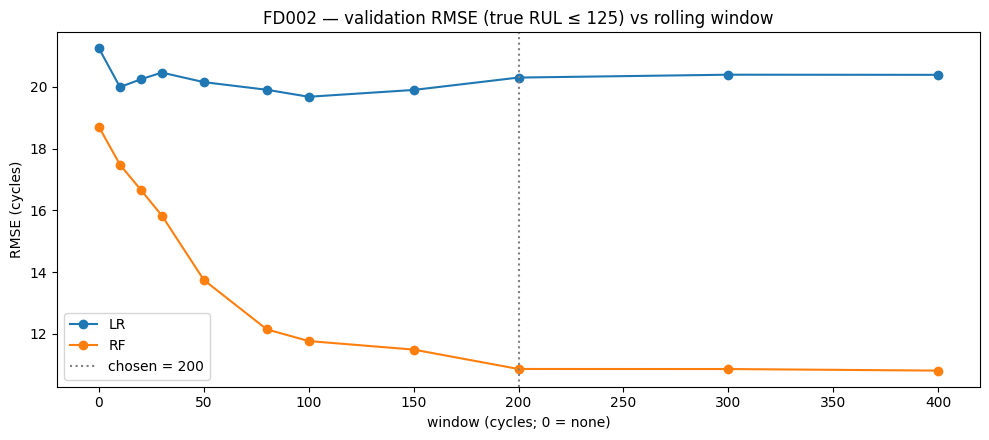

In [5]:
# Cell 5 — Window experiment
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

y = cuts.true_rul.values
LE = y <= 125

def probe_window(w, include_cycle):
    trf, names = fe.build_tabular(tr_s, B, w, include_cycle)
    vaf, _ = fe.build_tabular(va_s, B, w, include_cycle)
    X = fe.rows_at(vaf, cuts)[names]
    out = []
    for name, model in [("LR", LinearRegression()),
                        ("RF", RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features=0.33,
                                                     max_samples=0.5, n_jobs=-1, random_state=SEED))]:
        t0 = time.time()
        model.fit(trf[names], trf["RUL"])
        pred = np.clip(model.predict(X), 0, None)
        out.append({"window": w, "cycle_feat": include_cycle, "probe": name, "n_features": len(names),
                    "RMSE_le125": ev.rmse(y[LE], pred[LE]), "MAE_le125": ev.mae(y[LE], pred[LE]),
                    "bias_le125": float(np.mean(pred[LE] - y[LE])),
                    "NASA_per_point_le125": ev.nasa_score(y[LE], pred[LE]) / LE.sum(),
                    "RMSE_all": ev.rmse(y, pred), "fit_seconds": round(time.time() - t0, 1)})
    print(f"window {w:3d}, cycle={include_cycle}: LR {out[0]['RMSE_le125']:.2f} | RF {out[1]['RMSE_le125']:.2f}"
          f"  ({out[1]['fit_seconds']}s)")
    return out

rows = []
for w in [0, 10, 20, 30, 50, 80, 100, 150, 200, 300, 400]:
    rows += probe_window(w, include_cycle=True)
win = pd.DataFrame(rows)

rf = win[win.probe == "RF"].set_index("window")["RMSE_le125"]
WINDOW = int(min(w for w in rf.index if rf[w] <= rf.min() + 0.5))
print(f"\nBest RF window: {int(rf.idxmin())} ({rf.min():.2f}) → chosen by the 0.5 rule: {WINDOW} ({rf[WINDOW]:.2f})")

rows += probe_window(WINDOW, include_cycle=False)              # does `cycle` still help at the chosen window?
win = pd.DataFrame(rows)
win.to_csv(FE_REPORT / "window_experiment.csv", index=False)
on  = win[(win.window == WINDOW) & win.cycle_feat & (win.probe == "RF")].RMSE_le125.iloc[0]
off = win[(win.window == WINDOW) & ~win.cycle_feat & (win.probe == "RF")].RMSE_le125.iloc[0]
INCLUDE_CYCLE = bool(on <= off)
print(f"cycle feature at window {WINDOW}: with {on:.2f} vs without {off:.2f} → include_cycle = {INCLUDE_CYCLE}")

fig, ax = plt.subplots(figsize=(10, 4.5))
for probe, sub in win[win.cycle_feat].groupby("probe"):
    ax.plot(sub.window, sub.RMSE_le125, marker="o", label=probe)
ax.axvline(WINDOW, color="grey", ls=":", label=f"chosen = {WINDOW}")
ax.set(title="FD002 — validation RMSE (true RUL ≤ 125) vs rolling window", xlabel="window (cycles; 0 = none)",
       ylabel="RMSE (cycles)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "12_window_experiment.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation (local reference run; RF may differ by a few tenths in Colab):**

| Window | 0 | 10 | 20 | 30 | 50 | 80 | 100 | 150 | **200** | 300 | 400 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| LR RMSE ≤125 | 21.24 | 19.99 | 20.25 | 20.46 | 20.15 | 19.90 | 19.68 | 19.90 | **20.30** | 20.39 | 20.39 |
| RF RMSE ≤125 | 18.70 | 17.48 | 16.66 | 15.83 | 13.74 | 12.15 | 11.77 | 11.49 | **10.86** | 10.86 | 10.81 |

1. **FD002 needs much longer history than FD001.** The RF improves steadily up to about 200 cycles (18.7 → 10.9, about −42%) and is flat after that. Window 400 is longer than any engine's life, so it means "all history so far". By the 0.5 rule, **window = 200**: 300 and 400 are within 0.05 of it. Because most validation points have fewer than 200 cycles of history, in practice the features are "everything seen since cycle 1" for most engines.
2. **Why longer windows help here.** Per-regime z-scores still carry regime-dependent noise, so a 30-cycle mean is still noisy. A long mean gives each engine a stable **personal baseline**: how this particular engine has behaved so far. The current reading and short-term trend can then be compared against it. Manufacturing differences between engines are exactly what the dataset describes ("different degrees of initial wear").
3. **Linear Regression stays at about 20** whatever the window, the same as FD001. It can't use these features non-linearly.
4. **`cycle` still helps** at the chosen window (see the printed line).
5. **⚠️ Honest note about FD001:** in FD001 we stopped at window 30, on the grounds that the shortest test engine had 31 cycles. That reason was too strict, because `min_periods=1` makes longer windows work on short engines too. FD001 might also gain from a longer window. We **don't** change FD001 now: its test set has already been used once, and re-tuning after seeing the test results would bias it. If you want, we can revisit it later as a clearly-labelled extra experiment.

---
## Cell 6 — LSTM input experiment
The LSTM window can't be longer than **21 cycles**, because the shortest test engine has only 21 and we don't use padding (fake history). But Cell 5 shows FD002 needs about 100 cycles of context. So we compare three inputs:

| Variant | Each time step contains | Window |
|---|---|---|
| L15 | the 14 regime-scaled sensors | 15 cycles |
| L21 | the 14 regime-scaled sensors | 21 cycles |
| **L21 + means** | 14 sensors **+ their 14 rolling means over `WINDOW` cycles** | 21 cycles |

The third variant gives the LSTM the long-term baseline as an input, while it still reads the last 21 cycles step by step. The rolling means are computed causally, exactly as for the tree models.

**Probe setup:** a small LSTM (64 units, 1 layer), a **fixed 12 epochs** with no early stopping, so the validation points are used only for scoring and never for training decisions. We use **2 seeds** per variant, because one LSTM run can be noisy.

In [6]:
# Cell 6 — LSTM input probe
tr_r = fe.add_rolling_features(tr_s, B, WINDOW)
va_r = fe.add_rolling_features(va_s, B, WINDOW)
MEANS = [f"{c}_mean_{WINDOW}" for c in B]
VARIANTS = {"L15": (15, B), "L21": (21, B), "L21 + means": (21, B + MEANS)}

rows = []
for name, (L, cols) in VARIANTS.items():
    assert L <= MAX_SEQ
    X_tr, y_tr, _ = fe.make_sequences(tr_r, cols, L)
    X_cut = fe.sequences_at(va_r, cols, L, cuts)
    for seed in (42, 7):
        t0 = time.time()
        model, hist, _ = mt.train_lstm({"hidden": 64, "layers": 1}, X_tr, y_tr, CAP, epochs=12,
                                       device=DEVICE, seed=seed, verbose=False)
        pred = mt.lstm_predict(model, X_cut, CAP, DEVICE)
        rows.append({"variant": name, "seq_len": L, "n_inputs": len(cols), "seed": seed,
                     "train_windows": len(X_tr), "RMSE_le125": ev.rmse(y[LE], pred[LE]),
                     "bias_le125": float(np.mean(pred[LE] - y[LE])),
                     "NASA_per_point_le125": ev.nasa_score(y[LE], pred[LE]) / LE.sum(),
                     "final_train_loss": float(hist.train_loss.iloc[-1]), "seconds": round(time.time() - t0, 1)})
        print(f"{name:12s} seed {seed}: RMSE≤125 {rows[-1]['RMSE_le125']:.2f}  ({rows[-1]['seconds']}s)")

lstm_exp = pd.DataFrame(rows)
lstm_exp.to_csv(FE_REPORT / "lstm_input_experiment.csv", index=False)
summary = lstm_exp.groupby("variant", sort=False).agg(
    seq_len=("seq_len", "first"), n_inputs=("n_inputs", "first"), RMSE_mean=("RMSE_le125", "mean"),
    RMSE_min=("RMSE_le125", "min"), RMSE_max=("RMSE_le125", "max"), bias_mean=("bias_le125", "mean"))
display(summary.round(2))
LSTM_VARIANT = summary.RMSE_mean.idxmin()
print("Lowest mean RMSE:", LSTM_VARIANT)

L15          seed 42: RMSE≤125 19.62  (15.4s)
L15          seed 7: RMSE≤125 19.79  (7.0s)
L21          seed 42: RMSE≤125 20.35  (6.0s)
L21          seed 7: RMSE≤125 19.55  (7.0s)
L21 + means  seed 42: RMSE≤125 14.05  (6.1s)
L21 + means  seed 7: RMSE≤125 15.22  (7.0s)


,seq_len,n_inputs,RMSE_mean,RMSE_min,RMSE_max,bias_mean
variant,,,,,,
L15,15,14,19.70,19.62,19.79,9.12
L21,21,14,19.95,19.55,20.35,9.46
L21 + means,21,28,14.63,14.05,15.22,5.62


Lowest mean RMSE: L21 + means


**Interpretation (local CPU reference run; GPU runs differ slightly, and LSTMs are noisy):**

| Variant | RMSE ≤125 (seed 42 / 7) | Mean |
|---|---:|---:|
| L15 | 19.69 / 19.78 | 19.7 |
| L21 | 20.47 / 19.53 | 20.0 |
| **L21 + means (window 200)** | **14.14 / 15.26** | **14.7** |

1. **15 vs 21 cycles makes no real difference** (19.7 vs 20.0, within seed noise). Both are far too short to see FD002's wear through its noise.
2. **Adding the long rolling means cuts the error by about a quarter** (20 → 14.7). That matches Cell 5: FD002's signal lives in the long-term trend.
3. The two seeds of the "+ means" variant differ by about 1.1 RMSE, a reminder that a single LSTM run is noisy. Phase 5 will tune the architecture and use early stopping on an inner split, as in FD001.

### ⚠️ Decision for you: LSTM input for FD002
This changes the LSTM input compared with FD001 (sensors only), so it needs your approval:
- **Recommended: "L21 + means".** 21 cycles × 28 inputs (14 sensors + 14 rolling means over `WINDOW` cycles). It's clearly better on validation and still uses only past data. The API will compute the rolling means from the uploaded history, the same as for the tree models.
- **Alternative: "L21".** Keeps the LSTM identical in design to FD001 ("raw history only"), but it will very likely be the weakest of the four models on FD002.

Cell 7 uses the variant with the lowest mean RMSE. To force the FD001-style design, set `LSTM_VARIANT = "L21"` at the top of Cell 7.

## Cell 7 — Build the final LSTM sequences and check them

In [7]:
# Cell 7 — Final sequences (uncomment the next line to force the FD001-style design)
# LSTM_VARIANT = "L21"
SEQ_LEN, LSTM_FEATURES = VARIANTS[LSTM_VARIANT]
X_tr, y_tr, m_tr = fe.make_sequences(tr_r, LSTM_FEATURES, SEQ_LEN)
X_va, y_va, m_va = fe.make_sequences(va_r, LSTM_FEATURES, SEQ_LEN)
X_cut = fe.sequences_at(va_r, LSTM_FEATURES, SEQ_LEN, cuts)
print(f"Variant {LSTM_VARIANT}: train {X_tr.shape} | val {X_va.shape} | cut points {X_cut.shape}")
test_short = int((d["test"].groupby("engine_id").cycle.max() < SEQ_LEN).sum())
print("Test engines shorter than the window:", test_short)
assert test_short == 0

e0, c0 = m_tr.iloc[0]
raw = tr_r[tr_r.engine_id == e0].sort_values("cycle")
assert c0 == SEQ_LEN and np.allclose(X_tr[0], raw[LSTM_FEATURES].values[:SEQ_LEN]) and y_tr[0] == raw.RUL.values[SEQ_LEN - 1]
print(f"✅ Window 0 = engine {e0}, cycles 1–{c0}, label {y_tr[0]:.0f}")

Variant L21 + means: train (39046, 21, 28) | val (9513, 21, 28) | cut points (520, 21, 28)
Test engines shorter than the window: 0
✅ Window 0 = engine 1, cycles 1–21, label 125


**Expected (with "L21 + means"):** `train (39046, 21, 28) | val (9513, 21, 28) | cut points (520, 21, 28)`, then `Test engines shorter than the window: 0`, then `✅ Window 0 = engine 1, cycles 1–21, label 125`.

## Cell 8 — Freeze and save the feature configuration

In [8]:
# Cell 8 — feature_config.json (read by training, evaluation and the API)
tabular_names = fe.tabular_feature_names(B, WINDOW, INCLUDE_CYCLE)
feature_config = {
    "dataset": FD,
    "base_features": B,
    "preprocessing": "per-regime standardisation (models/FD002/preprocessing)",
    "tabular": {"window": WINDOW, "include_cycle": INCLUDE_CYCLE,
                "rolling_stats": ["mean", "std", "slope"], "min_periods": 1,
                "feature_order": tabular_names, "n_features": len(tabular_names)},
    "lstm": {"variant": LSTM_VARIANT, "seq_len": SEQ_LEN, "features": LSTM_FEATURES,
             "n_features": len(LSTM_FEATURES),
             "rolling_window": WINDOW if any("_mean_" in c for c in LSTM_FEATURES) else None,
             "label": "capped RUL at last cycle of window",
             "min_history_required": SEQ_LEN, "padding": "none (shorter histories rejected)"},
    "cycle_requirement": "cycle must count from the start of the engine's recorded operation (cycle 1)",
    "selection_evidence": [f"reports/feature_engineering/{FD}/window_experiment.csv",
                           f"reports/feature_engineering/{FD}/lstm_input_experiment.csv"],
}
(PROJECT_DIR / "models" / FD / "feature_config.json").write_text(json.dumps(feature_config, indent=2))
print(f"✅ Saved feature_config.json — tabular: {len(tabular_names)} features (window {WINDOW}), "
      f"LSTM: {SEQ_LEN}×{len(LSTM_FEATURES)} ({LSTM_VARIANT})")
print("First 3:", tabular_names[:3], "... Last 3:", tabular_names[-3:])

✅ Saved feature_config.json — tabular: 57 features (window 200), LSTM: 21×28 (L21 + means)
First 3: ['sensor_2', 'sensor_3', 'sensor_4'] ... Last 3: ['sensor_21_std_200', 'sensor_21_slope_200', 'cycle']


**Expected:** `✅ Saved feature_config.json — tabular: 57 features (window 200), LSTM: 21×28 (L21 + means)`.

---
## Summary — FD002 features (frozen)
| | FD001 | **FD002** |
|---|---|---|
| Base sensors | 14 (global scaling) | same 14 (**per-regime** scaling) |
| Tabular | window 30 + cycle → 57 | **window 200** + cycle → 57 |
| LSTM | 30 cycles × 14 sensors | **21 cycles × (14 sensors + 14 rolling means)** *(needs your approval)* |
| Shortest history the model needs | 30 | 21 |

